In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.var_model import VAR

In [2]:
spy   = pd.read_csv("spy_clean.csv",              parse_dates=["date"])
vix   = pd.read_csv("vix_clean.csv",              parse_dates=["date"])
y10   = pd.read_csv("dgs10_clean.csv",            parse_dates=["date"])
mag7  = pd.read_csv("mag7_clean.csv",             parse_dates=["date"])
asvi4 = pd.read_csv("AIStocks_ASVI4_Monthly.csv", parse_dates=["date"])

df = (spy
      .merge(vix,   on="date", how="inner")
      .merge(y10,   on="date", how="inner")
      .merge(asvi4, on="date", how="inner")
      .merge(mag7,  on="date", how="inner")
).sort_values("date").reset_index(drop=True)


print(f"Columns: {list(df.columns)}")
print(f"Shape: {df.shape}")
print(df[["date","ASVI4"]].head(6))

Columns: ['date', 'flow_spy', 'dlog_vix', 'dy10', 'ASVI4', 'mag7_ret']
Shape: (121, 6)
        date  ASVI4
0 2015-12-31    0.0
1 2016-01-31    0.0
2 2016-02-29    0.0
3 2016-03-31    0.0
4 2016-04-30    0.0
5 2016-05-31    0.0


In [3]:
from statsmodels.tsa.stattools import adfuller

cols = ["dlog_vix","dy10","ASVI4","flow_spy","mag7_ret"]
var_df      = df[cols+["date"]].dropna().copy()
var_df_2021 = var_df[var_df["date"] >= "2020-12-31"].copy()

print(f"Full sample : {len(var_df)} obs")
print(f"2021+       : {len(var_df_2021)} obs")

r = adfuller(var_df["ASVI4"], autolag="AIC")
print(f"\nADF ASVI4: stat={r[0]:.3f}  p={r[1]:.4f}  {'OK' if r[1]<0.05 else 'FAIL'}")

Full sample : 121 obs
2021+       : 61 obs

ADF ASVI4: stat=-7.322  p=0.0000  OK


In [4]:
def run_var_asvi(var_name, asvi_col, data):
    cols = ["dlog_vix","dy10", asvi_col,"flow_spy","mag7_ret"]
    idx  = {c:i for i,c in enumerate(cols)}
    sub  = data[cols].copy()

    print("\n" + "="*68)
    print(f"  {var_name}  |  N={len(sub)}")
    print("="*68)

    model   = VAR(sub)
    lag_sel = model.select_order(maxlags=4)
    print("\nLAG SELECTION:")
    print(lag_sel.summary())

    selected = max(lag_sel.bic, 1)
    print(f"BIC -> {lag_sel.bic}  |  AIC -> {lag_sel.aic}  |  Using: {selected}")

    results = model.fit(selected)
    print("\nVAR SUMMARY:")
    print(results.summary())

    print(f"\nStability      : {results.is_stable()}")
    print(f"Largest eigenvalue modulus : {1 / np.abs(results.roots).min():.4f}")

    print("\nGRANGER CAUSALITY:")
    print(f"{'Test':<38} {'F':>8}  {'p':>8}  Result")
    print("-"*65)
    for cause, effect, label in [
        (asvi_col,  "flow_spy",  f"{asvi_col} -> flow_spy"),
        (asvi_col,  "mag7_ret",  f"{asvi_col} -> mag7_ret"),
        ("flow_spy", "mag7_ret", "flow_spy -> mag7_ret"),
        ("mag7_ret",  asvi_col,  f"mag7_ret -> {asvi_col}"),
        ("dlog_vix",  "mag7_ret","VIX -> mag7_ret"),
        ("dy10",      "mag7_ret","dy10 -> mag7_ret"),
    ]:
        r   = results.test_causality(effect, [cause], kind="f")
        sig = "p<0.05" if r.pvalue<0.05 else ("p<0.10" if r.pvalue<0.10 else "--")
        print(f"{label:<38} {r.test_statistic:>8.3f}  {r.pvalue:>8.4f}  {sig}")

    print("\nWHITENESS (Portmanteau, nlags=10):")
    print(results.test_whiteness(nlags=10).summary())

    irf = results.irf(12)
    fig, axes = plt.subplots(1, 3, figsize=(15,4))
    for ax, (imp, resp, title) in zip(axes, [
        (asvi_col,  "mag7_ret", f"{asvi_col} -> mag7_ret"),
        (asvi_col,  "flow_spy", f"{asvi_col} -> flow_spy"),
        ("mag7_ret", asvi_col,  f"mag7_ret -> {asvi_col}"),
    ]):
        vals = irf.orth_irfs[:, idx[resp], idx[imp]]
        se   = irf.stderr(orth=True)[:, idx[resp], idx[imp]]
        h    = np.arange(len(vals))
        ax.plot(h, vals, color="navy", lw=2)
        ax.fill_between(h, vals-1.96*se, vals+1.96*se, alpha=0.2, color="steelblue")
        ax.axhline(0, color="black", lw=0.8, ls="--")
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Months after shock")
    plt.suptitle(f"Key IRFs — {var_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    fevd    = results.fevd(12)
    fevd_df = pd.DataFrame(fevd.decomp[idx["mag7_ret"]], columns=cols)
    print(f"\nFEVD — mag7_ret:")
    print(f"{'Variable':<14}  {'t=1':>8}  {'t=6':>8}  {'t=12':>8}")
    print("-"*44)
    for v in cols:
        print(f"{v:<14}  {fevd_df[v].iloc[0]:>7.1%}  {fevd_df[v].iloc[5]:>7.1%}  {fevd_df[v].iloc[11]:>7.1%}")

    return results


  ASVI4 x SPY -- Full Sample  |  N=121

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.06     -19.94*   1.946e-09      -20.01
1      -20.48      -19.77   1.281e-09     -20.19*
2     -20.64*      -19.34  1.094e-09*      -20.11
3      -20.42      -18.54   1.360e-09      -19.66
4      -20.35      -17.87   1.482e-09      -19.34
-------------------------------------------------
BIC -> 0  |  AIC -> 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:46:02
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -19.8316
Nobs:                     120.000    HQIC:                  -20.2454
Log likelihood:           410.343    FPE:                1.2156

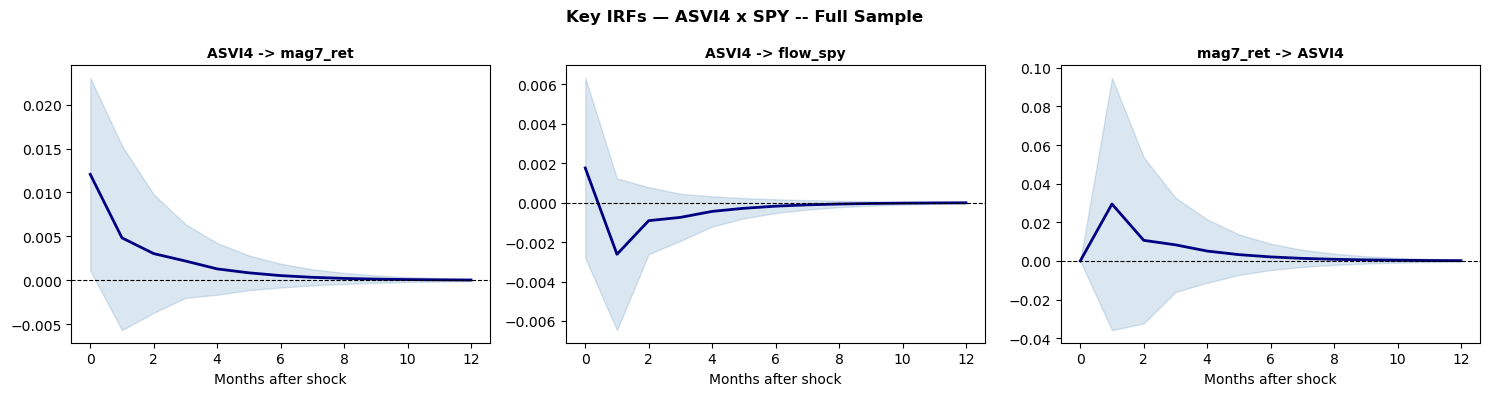


FEVD — mag7_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          29.2%    29.0%    29.0%
dy10               2.4%     2.5%     2.5%
ASVI4              2.6%     3.2%     3.3%
flow_spy           0.2%     0.3%     0.3%
mag7_ret          65.6%    64.9%    64.9%


In [5]:
res_asvi4_full = run_var_asvi(
    var_name = "ASVI4 x SPY -- Full Sample",
    asvi_col = "ASVI4",
    data     = var_df,
)


  ASVI4 x SPY -- 2021+  |  N=61

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.86     -19.68*   2.373e-09      -19.79
1      -20.40      -19.32   1.388e-09     -19.98*
2     -20.58*      -18.61  1.186e-09*      -19.81
3      -20.29      -17.43   1.662e-09      -19.18
4      -20.33      -16.57   1.779e-09      -18.87
-------------------------------------------------
BIC -> 0  |  AIC -> 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:46:02
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -19.1794
Nobs:                     60.0000    HQIC:                  -19.8170
Log likelihood:           211.117    FPE:                1.64874e-09
A

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


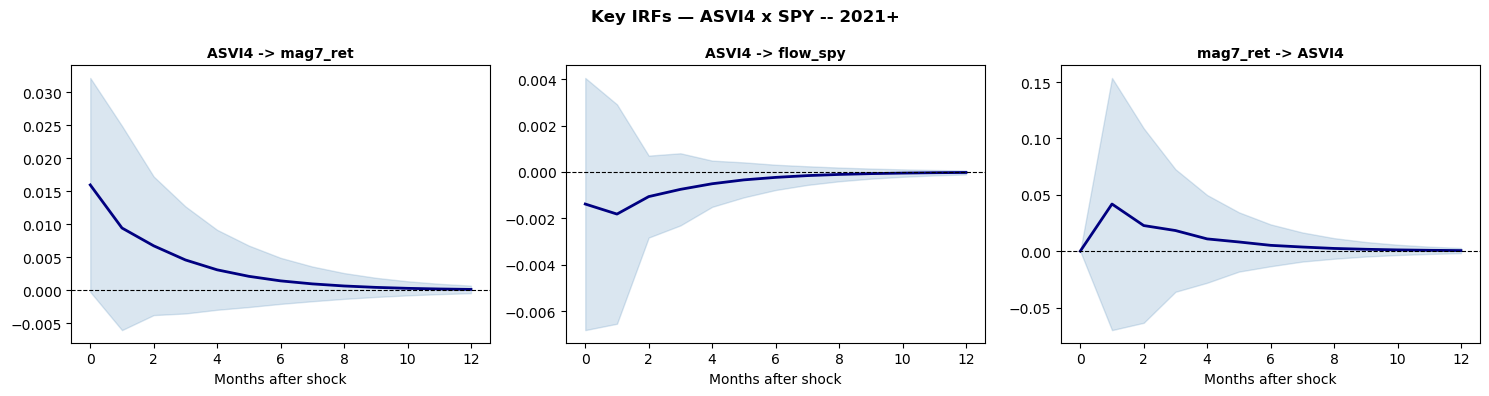


FEVD — mag7_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          28.1%    27.6%    27.6%
dy10               6.6%     6.4%     6.4%
ASVI4              3.9%     6.3%     6.4%
flow_spy           0.2%     0.7%     0.7%
mag7_ret          61.1%    59.0%    58.9%


In [6]:
res_asvi4_2021 = run_var_asvi(
    var_name = "ASVI4 x SPY -- 2021+",
    asvi_col = "ASVI4",
    data     = var_df_2021,
)